# Do LMS, EVC and wellness improve predictions?

Updated exploratory study with posterior simulation, actual Gibbs MCMC, posterior probabilities and temporal ablations. The original DAG notebook and results are preserved. This notebook runs from the **existing processed table**, without the excluded raw ZIP. It does **not** analyze the unavailable separate MLC RETRO export. See `POSTERIOR_STUDY.md` for the diagnosis.

The outcome CPD is Bayesian regression. With complete predictors it matches the original DAG outcome CPD. All-student comparisons here fill missing inputs using training medians; they do not perform full Bayesian joint-DAG missing-data inference. All preprocessing is learned on training terms only.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from posterior_study.analysis import run, ROOT
out = ROOT / 'posterior_results'
provenance = run(out)


  context            group      MAE     RMSE     NLPD  coverage90   width90  Brier70
  Block A         Baseline 3.606732 4.953306 3.007692    0.947238 16.118991 0.061474
  Block A LMS+EVC+Wellness 3.695247 5.092893 3.029915    0.947238 16.572663 0.062136
  Block B         Baseline 2.948496 3.933906 2.760601    0.906105 11.688055 0.059105
  Block B LMS+EVC+Wellness 3.036400 4.009700 2.773535    0.911047 12.079403 0.058910
No grades         Baseline 6.537705 8.720840 3.634391    0.893605 26.722305 0.106377
No grades LMS+EVC+Wellness 6.523802 8.454407 3.609560    0.906541 26.311682 0.098094
  context      comparison     base         extended  macro_MAE_gain  gain_lower95  gain_upper95  BB_P_gain_gt0  BB_P_gain_gt_0_5  terms_improved  macro_NLPD_gain
No grades add_to_baseline Baseline LMS+EVC+Wellness        0.013903     -0.115035      0.139569        0.57815               0.0               2         0.024831
  Block A add_to_baseline Baseline LMS+EVC+Wellness       -0.088514     -0.187656

## Same-student comparisons across four later terms
Train on the first two terms, predict the third, then expand training one term at a time. There are 146 evaluation rows per model and 24 models per run: all eight combinations of the three non-grade groups in each of three grade contexts. Grade availability dates are unverified; these are **retrospective bundles**, not verified week-4 forecasts. Precision 10 is inherited from the explored original workflow, not newly tuned on an untouched test set. All results are exploratory.

Macro MAE gives each evaluation term equal weight. The no-grades baseline is the earlier-student mean; other baselines use the stated grade bundle.

,context,group,MAE,RMSE,NLPD,coverage90,width90,Brier70
0,Block A,Baseline,3.6067,4.9533,3.0077,0.9472,16.1190,0.0615
5,Block A,LMS+EVC+Wellness,3.6952,5.0929,3.0299,0.9472,16.5727,0.0621
8,Block B,Baseline,2.9485,3.9339,2.7606,0.9061,11.6881,0.0591
13,Block B,LMS+EVC+Wellness,3.0364,4.0097,2.7735,0.9110,12.0794,0.0589
16,No grades,Baseline,6.5377,8.7208,3.6344,0.8936,26.7223,0.1064
21,No grades,LMS+EVC+Wellness,6.5238,8.4544,3.6096,0.9065,26.3117,0.0981


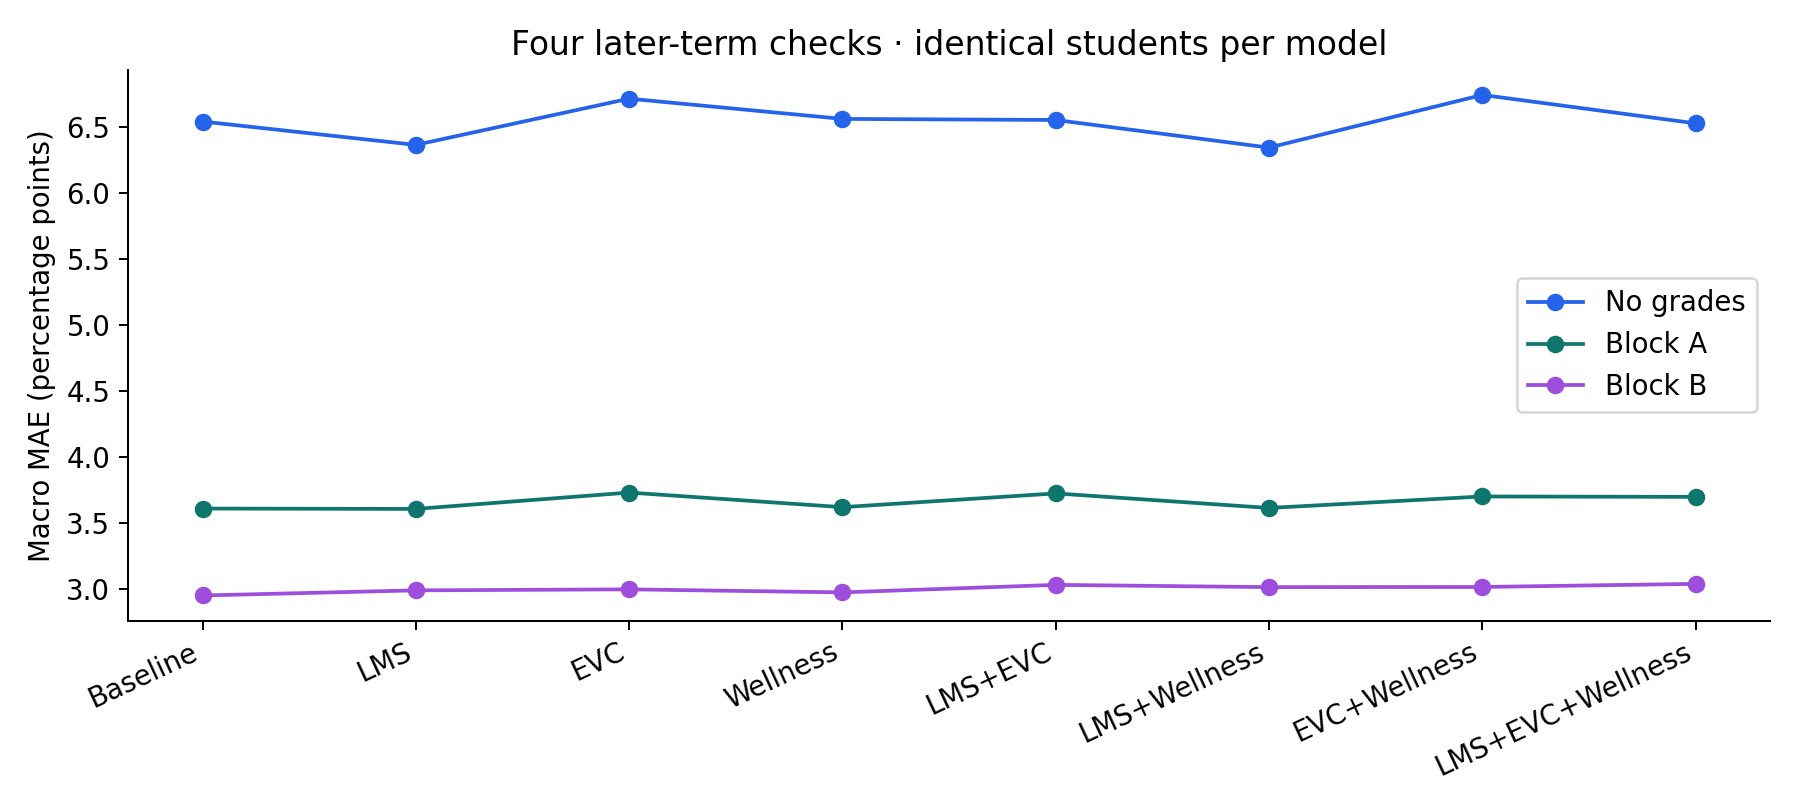

In [2]:
macro = pd.read_csv(out / 'macro_metrics.csv')
display(macro[macro['group'].isin(['Baseline', 'LMS+EVC+Wellness'])].round(4))
display(Image(filename=str(out / 'ablation_mae.png')))


## Paired gains and uncertainty
Gain = baseline absolute error minus extended-model absolute error; positive is better. The Bayesian bootstrap weights the **four observed term mean gains** using Dirichlet(1,1,1,1). Its probabilities concern reweighting these observed terms, not coefficient posteriors or the chance of success in a new term. Overlapping training sets and only four evaluation terms limit inference. The 0.5-point practical-gain target is illustrative, not an agreed educational requirement. A reported Monte Carlo probability of zero is not proof of impossibility.

,context,comparison,base,extended,macro_MAE_gain,gain_lower95,gain_upper95,BB_P_gain_gt0,BB_P_gain_gt_0_5,terms_improved,macro_NLPD_gain
20,Block B,add_to_baseline,Baseline,LMS,-0.0389,-0.0749,-0.0141,0.0000,0.0,0,-0.0003
21,Block B,add_to_baseline,Baseline,EVC,-0.0465,-0.1216,0.0117,0.0846,0.0,2,-0.0140
22,Block B,add_to_baseline,Baseline,Wellness,-0.0234,-0.0633,-0.0022,0.0004,0.0,1,-0.0040
23,Block B,add_to_baseline,Baseline,LMS+EVC,-0.0804,-0.1353,-0.0497,0.0000,0.0,0,-0.0139
24,Block B,add_to_baseline,Baseline,LMS+Wellness,-0.0633,-0.0935,-0.0288,0.0000,0.0,0,-0.0049
25,Block B,add_to_baseline,Baseline,EVC+Wellness,-0.0645,-0.1450,0.0206,0.0824,0.0,2,-0.0135
26,Block B,add_to_baseline,Baseline,LMS+EVC+Wellness,-0.0879,-0.1508,-0.0285,0.0000,0.0,0,-0.0129
27,Block B,add_last_LMS,EVC+Wellness,LMS+EVC+Wellness,-0.0234,-0.0569,-0.0018,0.0112,0.0,1,0.0005
28,Block B,add_last_EVC,LMS+Wellness,LMS+EVC+Wellness,-0.0246,-0.1155,0.0470,0.3090,0.0,2,-0.0081
29,Block B,add_last_Wellness,LMS+EVC,LMS+EVC+Wellness,-0.0075,-0.0533,0.0245,0.4055,0.0,2,0.0010


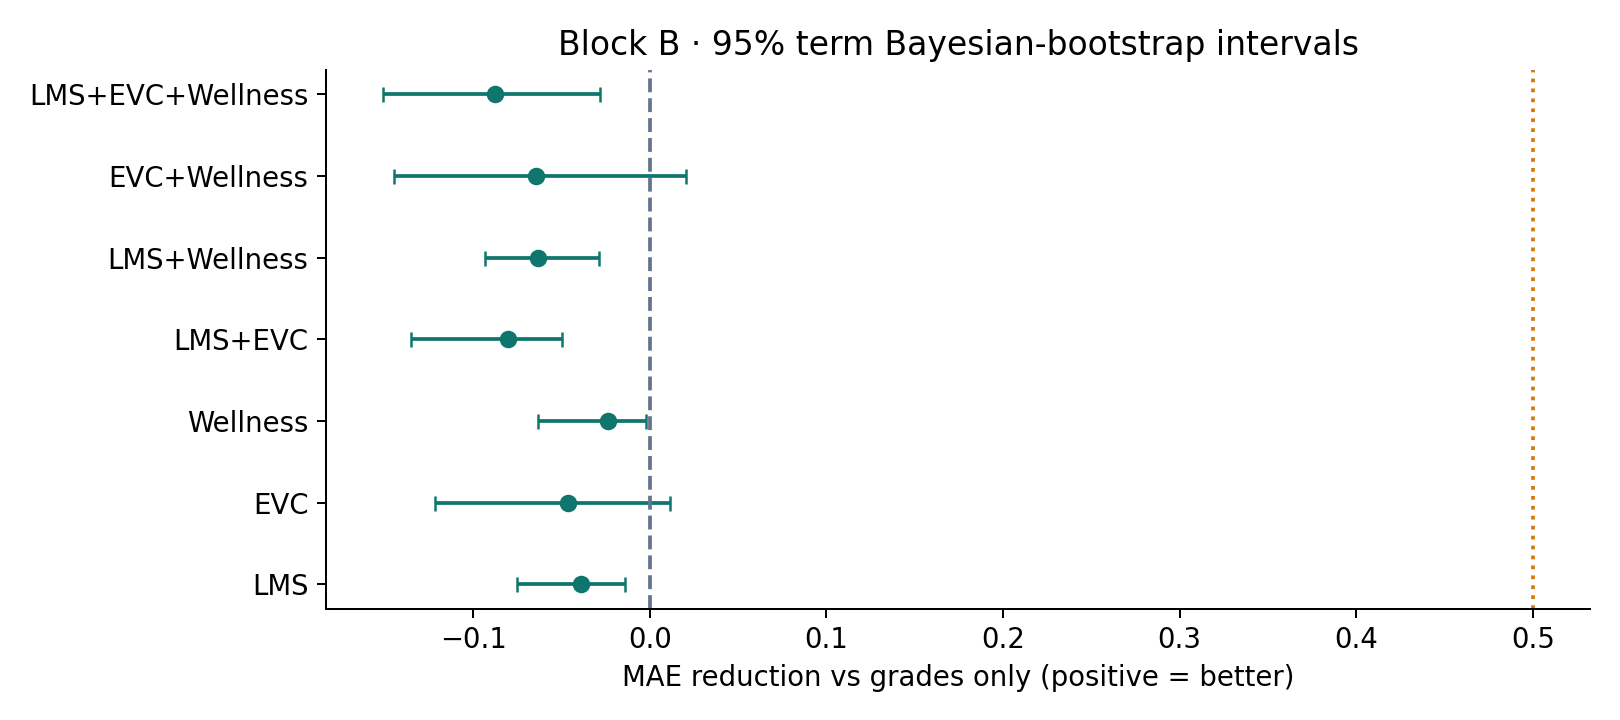

,sensitivity,context,comparison,base,extended,macro_MAE_gain,gain_lower95,gain_upper95,BB_P_gain_gt0,BB_P_gain_gt_0_5,terms_improved,macro_NLPD_gain
6,precision_1,No grades,add_to_baseline,Baseline,LMS+EVC+Wellness,-0.0992,-0.3026,0.1124,0.2143,0.0,2,0.0025
16,precision_1,Block A,add_to_baseline,Baseline,LMS+EVC+Wellness,-0.1148,-0.2435,0.0030,0.0295,0.0,1,-0.0278
26,precision_1,Block B,add_to_baseline,Baseline,LMS+EVC+Wellness,-0.1908,-0.3058,-0.0546,0.0008,0.0,1,-0.0281
36,precision_100,No grades,add_to_baseline,Baseline,LMS+EVC+Wellness,0.0818,0.0274,0.1269,1.0000,0.0,3,0.0322
46,precision_100,Block A,add_to_baseline,Baseline,LMS+EVC+Wellness,-0.0386,-0.0944,-0.0005,0.0222,0.0,2,-0.0006
56,precision_100,Block B,add_to_baseline,Baseline,LMS+EVC+Wellness,-0.0069,-0.0523,0.0714,0.3608,0.0,1,-0.0010
66,missingness_indicators,No grades,add_to_baseline,Baseline,LMS+EVC+Wellness,-0.0134,-0.1857,0.1491,0.4570,0.0,2,0.0215
76,missingness_indicators,Block A,add_to_baseline,Baseline,LMS+EVC+Wellness,-0.0619,-0.1558,0.0307,0.1035,0.0,1,-0.0235
86,missingness_indicators,Block B,add_to_baseline,Baseline,LMS+EVC+Wellness,-0.1193,-0.1805,-0.0503,0.0000,0.0,0,-0.0180
96,respondents_only,No grades,add_to_baseline,Baseline,LMS+EVC+Wellness,-0.0804,-0.3297,0.1458,0.2781,0.0,2,0.0013


,context,group,term,mean_abs_prediction_shift,max_abs_prediction_shift,fraction_shift_gt1
24,No grades,LMS+EVC+Wellness,2025 SPR,2.5823,7.2948,0.6744
25,No grades,LMS+EVC+Wellness,2025 FAL,2.9557,4.8155,0.9000
26,No grades,LMS+EVC+Wellness,2026 WTR,1.3531,4.4763,0.5500
27,No grades,LMS+EVC+Wellness,2026 SPR,1.9263,4.9532,0.7442
52,Block A,LMS+EVC+Wellness,2025 SPR,0.8657,3.4557,0.3023
53,Block A,LMS+EVC+Wellness,2025 FAL,0.4479,1.6434,0.1500
54,Block A,LMS+EVC+Wellness,2026 WTR,0.6007,1.5490,0.2000
55,Block A,LMS+EVC+Wellness,2026 SPR,0.6210,1.5272,0.2093
80,Block B,LMS+EVC+Wellness,2025 SPR,0.3922,1.2115,0.0233
81,Block B,LMS+EVC+Wellness,2025 FAL,0.3071,0.8820,0.0000


In [3]:
gains = pd.read_csv(out / 'paired_gain_summary.csv')
display(gains[gains['context'].eq('Block B')].round(4))
display(Image(filename=str(out / 'paired_gains.png')))
sensitivity = pd.read_csv(out / 'sensitivity_gains.csv')
display(sensitivity[sensitivity['comparison'].eq('add_to_baseline') & sensitivity['extended'].eq('LMS+EVC+Wellness')].round(4))

# Output influence is separate from error reduction.
shifts = pd.read_csv(out / "prediction_shift_summary.csv")
display(shifts[shifts["group"].eq("LMS+EVC+Wellness")].round(4))


## Posterior probabilities of conditional associations
Final fit uses the earlier 148 students. A coefficient measures final percentage points per one training standard deviation, holding other predictors fixed. `P_positive` and `P_abs_gt_1point` are analytic Student-t posterior probabilities conditional on the model, prior and imputed design. Continuous shrinkage priors do not supply an edge-inclusion probability. Neither probability is a causal effect or a guarantee of predictive improvement. The source field `cost` was renamed `cost_support` in the original pipeline; its questionnaire scoring is not newly validated here.

,feature,mean_points_per_SD,lower95,upper95,P_positive,P_abs_gt_1point
0,log_page_views,0.3379,-0.2072,0.8829,0.8887,0.0088
1,log_lms_participations,-0.0950,-0.6320,0.4421,0.3637,0.0006
2,cost_support,-0.2144,-0.8405,0.4117,0.2499,0.0072
3,expectancy,-0.0502,-0.7033,0.6029,0.4398,0.0032
4,value,-0.1301,-0.7348,0.4747,0.3357,0.0027
5,wellness,0.1956,-0.3875,0.7787,0.7457,0.0036


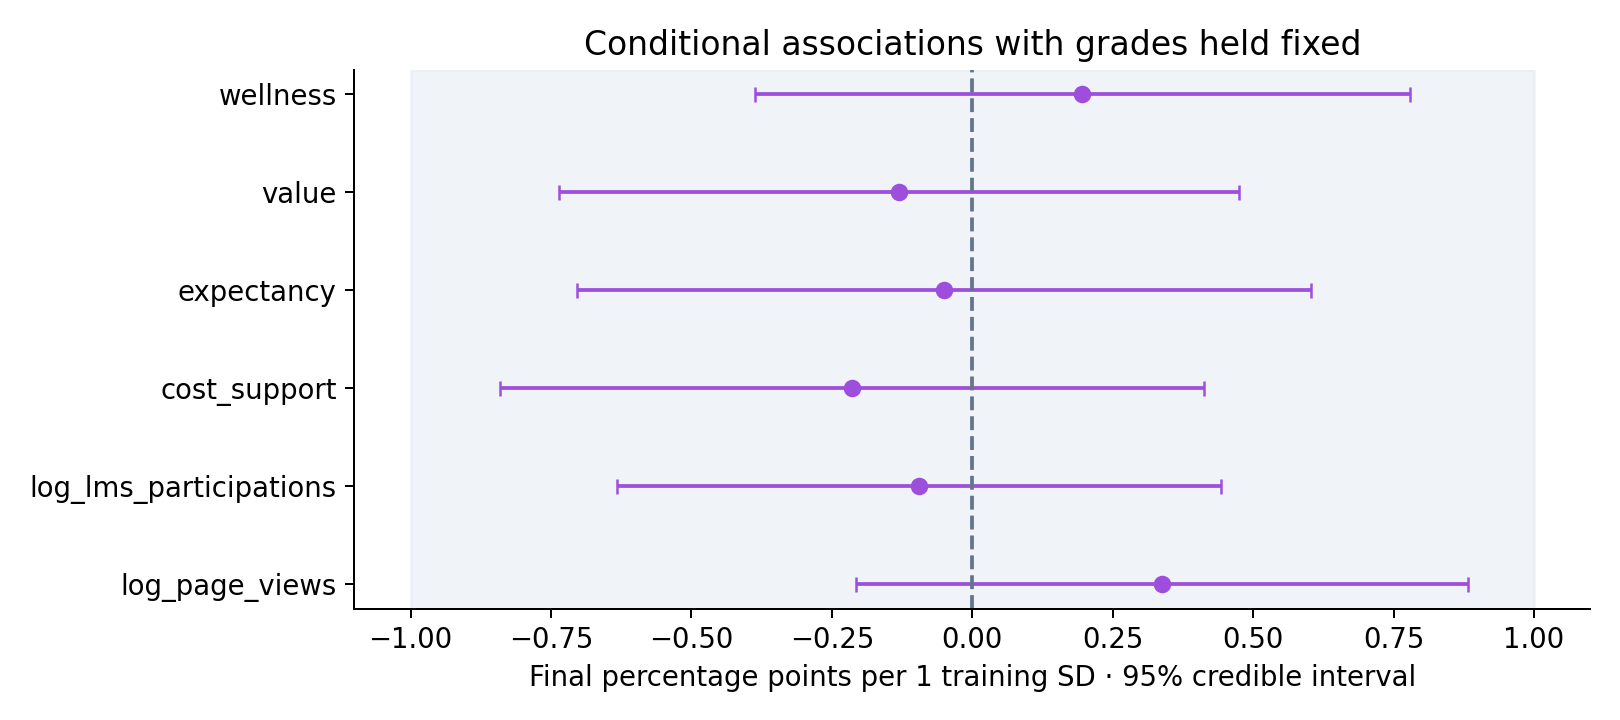

In [4]:
coefficients = pd.read_csv(out / 'coefficient_posteriors.csv')
display(coefficients.head(6).round(4))
display(Image(filename=str(out / 'coefficient_posteriors.png')))


## Simulation and MCMC validation
20,000 independent NIG draws provide an exact-posterior simulation reference. Four **Gibbs chains**, each with 1,000 warmup and 4,000 retained iterations, alternately sample coefficients and residual variance. Rank-normalized split/folded R-hat, bulk/tail ESS and Monte Carlo standard errors check agreement with the analytic posterior. This is outcome-CPD MCMC conditional on the imputed design, not structure learning or a full latent-data DAG sampler. MCMC is not necessary for this conjugate model. It becomes useful for nonconjugate hierarchical, robust or explicit missing-data models.

,parameter,rank_split_Rhat,bulk_ESS,tail_ESS,mean_MCSE,MCMC_mean,exact_mean,mean_error_in_MCSE
0,intercept,1.0000,15634.3662,15358.6155,0.0003,-0.0001,0.0000,0.5273
1,log_page_views,1.0001,15729.6452,15505.3961,0.0003,0.0438,0.0432,2.0031
2,log_lms_participations,1.0003,15113.1886,15601.6815,0.0003,-0.0126,-0.0122,1.4783
3,cost_support,1.0001,16000.0000,15036.7558,0.0003,-0.0278,-0.0274,1.2514
4,expectancy,1.0002,16000.0000,16000.0000,0.0003,-0.0063,-0.0064,0.4677
5,value,1.0001,15999.6401,15125.8913,0.0003,-0.0167,-0.0166,0.0917
6,wellness,1.0000,15778.6480,15844.3887,0.0003,0.0251,0.0250,0.2301
7,nspe_pct,0.9999,15774.2924,15280.8255,0.0003,0.0528,0.0525,0.9377
8,quiz1_comm_pct,1.0000,15921.2851,15733.3609,0.0005,0.0156,0.0160,0.7189
9,quiz1_ethics_pct,1.0001,15764.1217,14827.8795,0.0005,0.0693,0.0684,1.7338


{'mean_abs_risk_MC_error': 0.0001542832660273291,
 'max_abs_risk_MC_error': 0.0022802585438955678,
 'draws': 20000,
 'max_Rhat': 1.0007430767614252,
 'min_bulk_ESS': 12194.234321545597,
 'min_tail_ESS': 14735.091096685057,
 'max_mean_error_in_MCSE': 2.0030648375828513,
 'max_CI_error_in_posterior_scale': 0.040448292743825165}

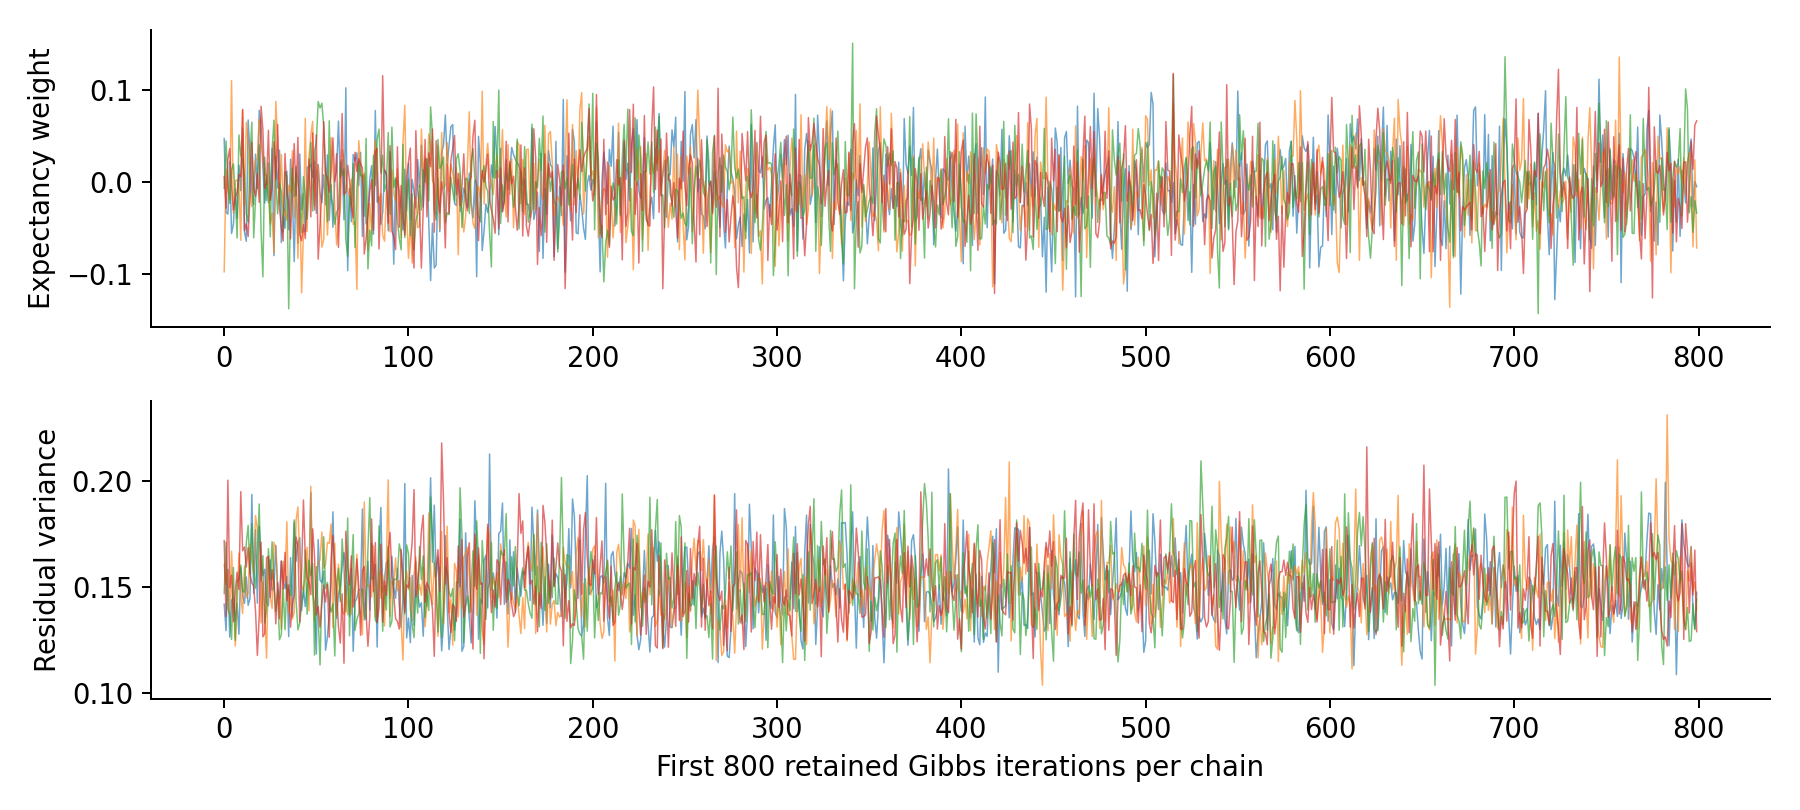

In [5]:
diagnostics = pd.read_csv(out / 'mcmc_diagnostics.csv')
display(diagnostics.round(4))
display(provenance['simulation_checks'])
display(Image(filename=str(out / 'gibbs_trace.png')))


## Student outcome probabilities and checks
The exact posterior predictive distribution is Student-t. `P_final_below70` includes coefficient, variance and new-outcome noise under the fixed imputed design. The 70% threshold is illustrative, not an official pass/fail policy. Risk probabilities are *not* certainty about an individual; some low outcomes are badly missed. Training posterior predictive checks are model-fit diagnostics, not held-out calibration evidence. Only a few low outcomes are available, so Brier scores cannot establish safe early-warning performance.

In [6]:
risk = pd.read_csv(out / 'spring2026_probabilities.csv')
display(risk.sort_values('P_final_below70', ascending=False).head(6).round(4))
display(provenance['posterior_predictive_checks'])


,student_id,cohort,percentage,predictive_mean,lower90,upper90,P_final_below70,MC_P_final_below70,n_imputed
0,MLCStudent24,2026 SPR,20.01,45.9098,39.3331,52.4866,1.0000,1.0000,4
7,MLCStudent122,2026 SPR,75.95,71.2359,65.7243,76.7474,0.3555,0.3551,0
3,MLCStudent18,2026 SPR,75.13,71.4584,65.4982,77.4187,0.3430,0.3424,0
4,MLCStudent162,2026 SPR,75.48,74.7223,68.7248,80.7197,0.0973,0.0970,0
2,MLCStudent67,2026 SPR,74.57,76.1137,70.2751,81.9523,0.0426,0.0448,4
1,MLCStudent63,2026 SPR,68.03,77.5965,71.3638,83.8293,0.0227,0.0211,4


{'sd': {'observed': 7.8147909070627275,
  'replicated_lower95': 7.183267233725614,
  'replicated_upper95': 8.505153598270038,
  'posterior_predictive_tail': 0.52045},
 'min': {'observed': 50.2,
  'replicated_lower95': 45.2166727335329,
  'replicated_upper95': 57.49636092423777,
  'posterior_predictive_tail': 0.67965},
 'n_below70': {'observed': 19.0,
  'replicated_lower95': 11.0,
  'replicated_upper95': 21.0,
  'posterior_predictive_tail': 0.1723},
 'unbounded_support': {'fraction_draws_outside_0_100': 0.00038648648648648647}}

## Diagnosis
The Bayesian framework is useful for uncertainty and transparent conditional forecasts. These data do not show meaningful added MAE value from all three non-grade sources beyond the larger grade bundle. LMS alone reduces no-grades macro MAE by 0.177 points and helps in all four terms; LMS + wellness gives 0.198 points. The all-source no-grades gain is only 0.014 points and is sensitive to prior choice. These explored source comparisons do not establish a winning early-course model. Posterior sampling validates computation, not model assumptions.

78/191 students lack early surveys. Median filling omits missing-data uncertainty; respondent-only checks select a different population. The Gaussian likelihood is unbounded and the existing model misses an extreme Spring 2026 outcome. Assessment scores are components of the final grade and their release dates are unknown. A better forecasting model need not identify a causal DAG. EVC associations, data-source utility, and coaching benefit are separate questions.

Use these six existing terms for exploratory capstone evidence. Recover dated grade snapshots and the raw retrospective survey before making timing claims or adding RETRO predictors. If it was collected after the prediction checkpoint, RETRO belongs in a separately labeled retrospective analysis. A new class would strengthen confirmation, but is not required to complete this exploratory study.